# Pause, persist, repair

**Week 13 · Session 2**

Last session the graph ran start to finish on its own. Real systems need three more things:

| | What it gives you | LangGraph piece |
|---|---|---|
| **Pause** | stop mid-run, show a human something, carry on with their answer | `interrupt()` + `Command(resume=…)` |
| **Persist** | the pause survives a restart, a deploy, a weekend | a durable checkpointer (`SqliteSaver`) |
| **Repair** | a loop that checks its own work against something real and tries again | a back-edge with a budget |

You've met pieces of this before: Week 10's `input()` approval gate, Week 11's `RunState`,
Week 12's `HumanInTheLoopMiddleware`. Today you build the mechanism those were hiding.

**Today's project:** a coding agent that takes a Nimbus ticket, has a human approve its plan,
writes the code, runs **tests it has never seen**, debugs its own failures — and asks a
human for help when it's stuck.

In [1]:
%pip install -q "langchain==1.4.2" "langchain-openai==1.6.2" "langgraph==1.2.11" "langgraph-checkpoint-sqlite==3.1.1" python-dotenv

In [2]:
import os, json, re, ast, sys, time, sqlite3, operator, subprocess, tempfile, getpass
from pathlib import Path
from typing import Annotated, Literal, TypedDict

try:
    from dotenv import load_dotenv, find_dotenv
    load_dotenv(find_dotenv(usecwd=True) or Path.cwd().parent / ".env")
except ImportError:
    pass
if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API key: ")

# Anaconda 'base' fix (same as Week 11). httpx2 2.12+ decompresses brotli with output_buffer_limit=... as a keyword.
# Anaconda's brotli 1.x exposes process() as a C function that rejects kwargs
# ("TypeError: process() takes no keyword arguments"). Wrap it so OpenAI
# Responses (which often arrive Content-Encoding: br) can be decoded.
try:
    import brotli as _brotli
    from httpx2._decoders import BrotliDecoder as _BrotliDecoder
    _probe = _brotli.Decompressor()
    try:
        _probe.process(b"", output_buffer_limit=1)
    except TypeError:
        _brotli_init = _BrotliDecoder.__init__
        def _brotli_init_compat(self, *args, **kwargs):
            _brotli_init(self, *args, **kwargs)
            _impl = self._decompress
            self._decompress = lambda data, output_buffer_limit=None, **_k: _impl(data)
        _BrotliDecoder.__init__ = _brotli_init_compat
except Exception:
    pass

from IPython.display import Image, Markdown, display
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.prebuilt import ToolNode
from langchain.chat_models import init_chat_model
from langchain.messages import AIMessage, ToolMessage
from langchain.tools import tool

MODEL = "openai:gpt-4.1-mini"
llm = init_chat_model(MODEL, temperature=0)


def draw(graph):
    """Show a compiled graph as a picture (needs internet), or as Mermaid text without it."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())


print("ready")

ready


---
# Part 1 — `interrupt()`: the pause button

Call `interrupt(payload)` inside a node and the graph **stops right there**. The payload goes
back to whoever called `invoke` — show it to a human however you like: a notebook cell, a
Slack message, a web form. When they answer, you call `invoke(Command(resume=answer))` and
`interrupt()` **returns** their answer inside the node, as if it had been waiting all along.

It needs a checkpointer — the graph has to be saved somewhere while it waits.

In [3]:
class Refund(TypedDict, total=False):
    order_id: str
    amount_inr: int
    decision: str
    log: Annotated[list[str], operator.add]


def propose(r: Refund) -> dict:
    return {"amount_inr": 4999, "log": ["proposed INR 4999"]}


def manager_approval(r: Refund) -> dict:
    answer = interrupt({"question": "Approve this refund?", "order": r["order_id"], "amount_inr": r["amount_inr"]})
    return {"decision": answer, "log": [f"manager said: {answer}"]}


def pay(r: Refund) -> dict:
    return {"log": ["PAID" if r["decision"] == "yes" else "not paid"]}


b = StateGraph(Refund)
b.add_node("propose", propose)
b.add_node("manager_approval", manager_approval)
b.add_node("pay", pay)
b.add_edge(START, "propose"); b.add_edge("propose", "manager_approval")
b.add_edge("manager_approval", "pay"); b.add_edge("pay", END)
refunds = b.compile(checkpointer=InMemorySaver())

cfg = {"configurable": {"thread_id": "refund-1"}}
result = refunds.invoke({"order_id": "N104455", "log": []}, cfg)

print("paused?     ", "__interrupt__" in result)
print("payload     ", result["__interrupt__"][0].value)
print("waiting at  ", refunds.get_state(cfg).next)
print("log so far  ", result["log"])

paused?      True
payload      {'question': 'Approve this refund?', 'order': 'N104455', 'amount_inr': 4999}
waiting at   ('manager_approval',)
log so far   ['proposed INR 4999']


The run is **parked** at `manager_approval`. Nothing is blocking — no thread is waiting, no
`input()` is hanging. The state is in the checkpointer. You could answer in five seconds or
five days.

In [4]:
result = refunds.invoke(Command(resume="yes"), cfg)
print(result["log"])

['proposed INR 4999', 'manager said: yes', 'PAID']


### The one surprise: the node runs again from the top

When you resume, LangGraph **re-runs the paused node from its first line**; this time
`interrupt()` returns the answer instead of pausing. So any code *before* the `interrupt()`
runs twice.

In [5]:
EMAILS_SENT = []


def careless_approval(r: Refund) -> dict:
    EMAILS_SENT.append(f"emailed manager about {r['order_id']}")      # side effect BEFORE interrupt
    answer = interrupt({"question": "Approve?", "amount_inr": r["amount_inr"]})
    return {"decision": answer}


b = StateGraph(Refund)
b.add_node("propose", propose); b.add_node("careless_approval", careless_approval)
b.add_edge(START, "propose"); b.add_edge("propose", "careless_approval"); b.add_edge("careless_approval", END)
careless = b.compile(checkpointer=InMemorySaver())

cfg = {"configurable": {"thread_id": "refund-2"}}
careless.invoke({"order_id": "N104455", "log": []}, cfg)
careless.invoke(Command(resume="yes"), cfg)
print(EMAILS_SENT)

['emailed manager about N104455', 'emailed manager about N104455']


Two emails for one approval. The rule: **put side effects after the `interrupt()`, or in a
node of their own.** Anything before it must be safe to repeat — reading state, formatting
the question.

---
# Part 2 — Approve, edit or reject a tool call

Last week `HumanInTheLoopMiddleware` let you approve, edit or reject a tool call. Here is
that feature built by hand, so you can see there's no magic in it — and change it.

Nimbus billing support: a safe tool (`lookup_order`) and a risky one (`issue_refund`). Only
the risky one goes through a human gate.

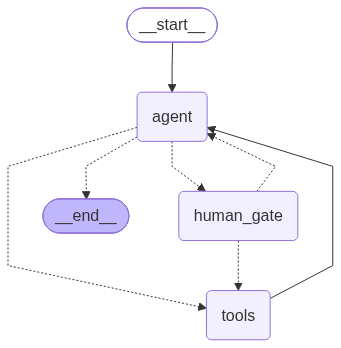

In [6]:
ORDERS = {
    "N104455": {"product": "Echo Bar", "paid_inr": 4999, "delivered": "3 days ago", "note": "charged twice"},
    "N104460": {"product": "Orbit", "paid_inr": 3999, "delivered": "2 days ago", "note": "customer reports a scratch"},
    "N104470": {"product": "Pulse X1", "paid_inr": 2499, "delivered": "20 days ago", "note": ""},
}
LEDGER = []          # the money that actually moved


@tool
def lookup_order(order_id: str) -> str:
    """Look up a Nimbus order: product, amount paid, when it was delivered, and any notes."""
    return json.dumps(ORDERS.get(order_id, "no such order"))


@tool
def issue_refund(order_id: str, amount_inr: int, reason: str) -> str:
    """Refund money to the customer. Moves real money."""
    LEDGER.append((order_id, amount_inr, reason))
    return f"Refunded INR {amount_inr} for {order_id}."


RISKY = {"issue_refund"}
support_tools = [lookup_order, issue_refund]
support_model = llm.bind_tools(support_tools, parallel_tool_calls=False)    # one call at a time: one decision at a time
SUPPORT_PROMPT = ("You are Nimbus billing support. Always look up the order first, then call issue_refund for what "
                  "the customer asks. Don't judge eligibility yourself and never say a refund is 'pending': a human "
                  "reviewer checks every issue_refund call before it runs, and you'll see their decision as the "
                  "tool's result. Then tell the customer the outcome in two sentences.")


def agent(state: MessagesState) -> dict:
    return {"messages": [support_model.invoke([{"role": "system", "content": SUPPORT_PROMPT}] + state["messages"])]}


def route(state: MessagesState) -> Literal["human_gate", "tools", "__end__"]:
    last = state["messages"][-1]
    if not last.tool_calls:
        return END
    if any(tc["name"] in RISKY for tc in last.tool_calls):
        return "human_gate"
    return "tools"


def human_gate(state: MessagesState) -> Command[Literal["tools", "agent"]]:
    last = state["messages"][-1]
    call = last.tool_calls[0]
    decision = interrupt({"tool": call["name"], "args": call["args"]})

    if decision["type"] == "approve":
        return Command(goto="tools")
    if decision["type"] == "edit":                      # same message id -> add_messages REPLACES the tool call
        edited = AIMessage(content=last.content, id=last.id, tool_calls=[{**call, "args": decision["args"]}])
        return Command(goto="tools", update={"messages": [edited]})
    # reject: answer the tool call ourselves, so the model hears why
    refusal = ToolMessage(f"A human reviewer REJECTED this refund: {decision['message']}", tool_call_id=call["id"])
    return Command(goto="agent", update={"messages": [refusal]})


def build_support(checkpointer):
    b = StateGraph(MessagesState)
    b.add_node("agent", agent)
    b.add_node("tools", ToolNode(support_tools))
    b.add_node("human_gate", human_gate)
    b.add_edge(START, "agent")
    b.add_conditional_edges("agent", route)
    b.add_edge("tools", "agent")
    return b.compile(checkpointer=checkpointer)


support = build_support(InMemorySaver())
draw(support)

Two new things in `human_gate`:

- It returns a **`Command(goto=…, update=…)`** — the node picks the next node *and* updates
  state in one go. The `Command[Literal["tools", "agent"]]` annotation tells LangGraph where it
  can go, so the picture is right.
- **Edit** works because of Session 1's reducer lesson: a message with the **same id**
  replaces the old one, so the tool call the tools node runs is the edited one.

A helper to run a turn and show either the pause or the answer:

In [7]:
def turn(graph, thread, message=None, resume=None):
    cfg = {"configurable": {"thread_id": thread}}
    if resume is not None and not graph.get_state(cfg).next:
        print("nothing is waiting for a human on thread", thread)
        return
    inp = Command(resume=resume) if resume is not None else {"messages": [{"role": "user", "content": message}]}
    out = graph.invoke(inp, cfg)
    if "__interrupt__" in out:
        print("⏸  waiting for a human:", out["__interrupt__"][0].value)
    else:
        print("💬", out["messages"][-1].content)


turn(support, "A", "I was charged twice for order N104455. Please refund the extra charge.")

⏸  waiting for a human: {'tool': 'issue_refund', 'args': {'order_id': 'N104455', 'amount_inr': 4999, 'reason': 'Charged twice for the same order'}}


In [8]:
turn(support, "A", resume={"type": "approve"})

💬 I have processed a refund of INR 4999 for the extra charge on your order N104455. You should see the amount credited back to your original payment method shortly.


**Edit.** A scratch is worth a goodwill refund, not the full price. The reviewer changes the
amount before the tool runs.

In [9]:
turn(support, "B", "My Orbit (order N104460) arrived with a scratch. I want a full refund.")

⏸  waiting for a human: {'tool': 'issue_refund', 'args': {'order_id': 'N104460', 'amount_inr': 3999, 'reason': 'Product arrived with a scratch'}}


In [10]:
turn(support, "B", resume={"type": "edit",
                           "args": {"order_id": "N104460", "amount_inr": 500, "reason": "goodwill: cosmetic scratch"}})

💬 Your order N104460 for the Orbit was delivered 2 days ago and you reported a scratch. A partial refund of INR 500 has been processed for you; please check your account for the update.


**Reject.** Delivered 20 days ago — outside the 7-day return window. The reviewer rejects with
a reason, and the model hears it as the tool's result.

In [11]:
turn(support, "C", "Refund order N104470 please, I don't like the colour.")

⏸  waiting for a human: {'tool': 'issue_refund', 'args': {'order_id': 'N104470', 'amount_inr': 2499, 'reason': 'Customer does not like the colour'}}


In [12]:
turn(support, "C", resume={"type": "reject",
                           "message": "Outside the 7-day return window. Offer a repair or replacement under the 12-month warranty only if it's faulty."})

💬 The refund request for order N104470 was reviewed but cannot be approved as it is outside the 7-day return window. If the product is faulty, I can assist with a repair or replacement under the 12-month warranty.


In [13]:
print("Money that actually moved:")
for row in LEDGER:
    print("  ", row)

Money that actually moved:
   ('N104455', 4999, 'Charged twice for the same order')
   ('N104460', 500, 'goodwill: cosmetic scratch')


Three requests, two refunds, and neither is the amount the model first asked for in case B.
The **ledger is the proof**: the risky tool only ran after a human said yes, with the
arguments the human chose.

---
# Part 3 — A pause that survives a restart

`InMemorySaver` lives in this Python process. Restart the kernel, and every paused
approval is gone. For anything real you need a checkpointer that writes to disk or a database.
`SqliteSaver` is the same interface, backed by a file.

In [14]:
DB = Path("support_checkpoints.db")
DB.unlink(missing_ok=True)                      # start clean each time the notebook runs

conn = sqlite3.connect(DB, check_same_thread=False)
support_db = build_support(SqliteSaver(conn))

turn(support_db, "D", "Order N104455 was charged twice, please refund the duplicate.")

⏸  waiting for a human: {'tool': 'issue_refund', 'args': {'order_id': 'N104455', 'amount_inr': 4999, 'reason': 'Duplicate charge for order N104455'}}


Now simulate a restart: close the database connection and throw the graph away. (In class,
you could really restart the kernel here — just rerun the setup cells and the next one.)

In [15]:
conn.close()
del support_db

# --- a brand-new process: new connection, new graph object, same file ---
conn = sqlite3.connect(DB, check_same_thread=False)
saver = SqliteSaver(conn)
support_db = build_support(saver)

# An approvals inbox: every thread that is parked at the human gate.
threads = {c.config["configurable"]["thread_id"] for c in saver.list(None)}
for t in sorted(threads):
    snap = support_db.get_state({"configurable": {"thread_id": t}})
    if snap.next:
        print(f"thread {t}: waiting at {snap.next} ->", snap.tasks[0].interrupts[0].value)

thread D: waiting at ('human_gate',) -> {'tool': 'issue_refund', 'args': {'order_id': 'N104455', 'amount_inr': 4999, 'reason': 'Duplicate charge for order N104455'}}


In [16]:
turn(support_db, "D", resume={"type": "approve"})

💬 The duplicate charge for order N104455 has been refunded for INR 4999. Please allow some time for the refund to reflect in your account.


The approval was given by a different graph object, over a different connection, to a run
that started "before the restart". That's what makes human-in-the-loop usable in production:
the human can take a day, and your server can redeploy in the meantime.

In production you'd use `langgraph-checkpoint-postgres` — the same interface again. The
`thread_id` becomes your ticket id, job id or conversation id.

---
# Part 4 — Project: a code agent that repairs itself

**The job.** A developer ticket comes in. The agent must:

1. **plan** — list the rules and edge cases it will handle;
2. **wait for a human to approve the plan** (`interrupt`) — the cheapest place to catch a misunderstanding;
3. **write the code**;
4. **check it statically** — refuse anything that imports what it shouldn't;
5. **run hidden tests** — written by QA, never shown to the agent;
6. if tests fail, **debug** and go back to 4 — at most `MAX_ATTEMPTS` times;
7. still failing? **ask a human for a hint** (`interrupt` again) — and that has a budget too.

This is Week 10's evaluation lesson turned into a loop: the model doesn't decide it's done,
**the tests do.**

## The ticket

Deliberately written the way real tickets are: short, and vague in places.

In [17]:
TICKET = """Ticket NIM-482 - add delivery_window(city, ordered_at, express=False) -> (earliest, latest)

Return ISO dates ('YYYY-MM-DD'). ordered_at looks like '2026-09-14 10:00'.
Shipping policy: metros (Mumbai, Delhi, Bengaluru, Chennai, Kolkata, Hyderabad) 1-3 days,
north-east (Guwahati, Shillong, Imphal, Agartala) 7-10 days, everywhere else 3-5 days.
Business days only - we don't deliver on Sundays or warehouse holidays (2026-10-02, 2026-11-09).
Orders after 6 pm go out the next day. Express halves the time; metros only.
Standard library only."""

Questions a careful engineer would ask: *is 18:00 "after 6 pm"? Does "1 day" mean tomorrow?
Halving 3 days gives 1.5 — round up or down? What does "metros only" do for Pune — error, or
ignore it? What if the next day is a holiday too?* The ticket doesn't say. **The tests do.**

## The hidden tests

QA's acceptance tests. They're written to a file next to the agent's code and run in a
separate process. The agent only ever sees **which calls failed** — the way you see CI output.

In [18]:
HIDDEN_TESTS = r'''
import json, sys
sys.path.insert(0, ".")
from solution import delivery_window

CASES = [   # (args, kwargs, expected)
    (("Mumbai", "2026-09-14 10:00"), {}, ("2026-09-15", "2026-09-17")),
    ((" pune ", "2026-09-14 10:00"), {}, ("2026-09-17", "2026-09-19")),
    (("Guwahati", "2026-09-14 10:00"), {}, ("2026-09-22", "2026-09-25")),
    (("Delhi", "2026-09-18 11:00"), {}, ("2026-09-19", "2026-09-22")),
    (("Chennai", "2026-09-19 19:30"), {}, ("2026-09-22", "2026-09-24")),
    (("Kolkata", "2026-09-16 18:00"), {}, ("2026-09-18", "2026-09-21")),
    (("Kolkata", "2026-09-16 17:59"), {}, ("2026-09-17", "2026-09-19")),
    (("Jaipur", "2026-09-20 09:00"), {}, ("2026-09-24", "2026-09-26")),
    (("HYDERABAD", "2026-09-17 12:00"), {"express": True}, ("2026-09-18", "2026-09-19")),
    (("Pune", "2026-09-17 12:00"), {"express": True}, "ValueError"),
    (("Shillong", "2026-09-26 20:00"), {}, ("2026-10-07", "2026-10-10")),
    (("Mumbai", "2026-10-01 19:00"), {}, ("2026-10-05", "2026-10-07")),
    (("Bengaluru", "2026-11-07 18:30"), {}, ("2026-11-11", "2026-11-13")),
]

failures = []
for args, kwargs, want in CASES:
    call = "delivery_window(" + ", ".join([repr(a) for a in args] + [f"{k}={v!r}" for k, v in kwargs.items()]) + ")"
    try:
        got = delivery_window(*args, **kwargs)
        got = tuple(got) if isinstance(got, (list, tuple)) else got
    except ValueError:
        got = "ValueError"
    except Exception as e:
        got = f"{type(e).__name__}: {e}"
    if got != want:
        failures.append(f"{call}: expected {want!r}, got {got!r}")
print(json.dumps({"total": len(CASES), "failures": failures}))
'''
N_TESTS = 13                       # len(CASES) in the hidden file
print(N_TESTS, "hidden tests")

13 hidden tests


## Running model-written code, carefully

Executing code a model wrote is the riskiest thing in this course. Three layers here:

- **A human approves the plan** before any code exists.
- **A static check** parses the code and refuses imports outside an allow-list and calls like
  `open`, `exec` or `eval` — before anything runs.
- **A separate process** in a throwaway folder, isolated mode (`python -I`), killed after 10 seconds.

That is **not a real sandbox** — a determined program could still do harm. In production
you'd run it in a container or a hosted sandbox with no network and no secrets. The shape of
the graph stays the same; only `run_hidden_tests` changes.

In [19]:
ALLOWED_IMPORTS = {"datetime", "math", "re", "calendar"}
FORBIDDEN_CALLS = {"open", "exec", "eval", "compile", "__import__", "input"}


def static_check(code: str) -> str:
    """Return '' if the code looks safe to run, else the reason it isn't."""
    try:
        tree = ast.parse(code)
    except SyntaxError as e:
        return f"SyntaxError: {e}"
    for node in ast.walk(tree):
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            mods = [a.name for a in node.names] if isinstance(node, ast.Import) else [node.module or ""]
            bad = [m for m in mods if m.split(".")[0] not in ALLOWED_IMPORTS]
            if bad:
                return f"import not allowed: {bad}. Allowed: {sorted(ALLOWED_IMPORTS)}"
        if isinstance(node, ast.Call) and getattr(node.func, "id", "") in FORBIDDEN_CALLS:
            return f"call not allowed: {node.func.id}()"
    if "def delivery_window" not in code:
        return "no function named delivery_window"
    return ""


def run_hidden_tests(code: str) -> dict:
    with tempfile.TemporaryDirectory() as folder:
        Path(folder, "solution.py").write_text(code)
        Path(folder, "test_hidden.py").write_text(HIDDEN_TESTS)
        try:
            p = subprocess.run([sys.executable, "-I", "test_hidden.py"], cwd=folder,
                               capture_output=True, text=True, timeout=10)
        except subprocess.TimeoutExpired:
            return {"total": N_TESTS, "failures": ["timed out after 10 seconds - an infinite loop?"]}
    if p.returncode != 0:
        return {"total": N_TESTS, "failures": [p.stderr.strip().splitlines()[-1]]}
    return json.loads(p.stdout)


print(static_check("import os\nos.remove('x')"))
print(static_check("def delivery_window(c, o, express=False):\n    return ('', '')"))
print(run_hidden_tests("def delivery_window(c, o, express=False):\n    return ('2026-09-15', '2026-09-17')")["failures"][:2])

import not allowed: ['os']. Allowed: ['calendar', 'datetime', 'math', 're']

["delivery_window(' pune ', '2026-09-14 10:00'): expected ('2026-09-17', '2026-09-19'), got ('2026-09-15', '2026-09-17')", "delivery_window('Guwahati', '2026-09-14 10:00'): expected ('2026-09-22', '2026-09-25'), got ('2026-09-15', '2026-09-17')"]


The last line is a "solution" that always returns the same dates: one test passes by luck,
the rest fail with a message a developer (or a model) can act on.

## The state

In [20]:
class Job(TypedDict, total=False):
    ticket: str
    plan: str
    plan_feedback: str       # from the human plan review
    code: str
    problem: str             # static-check error or failing tests: what the debugger sees
    report: dict
    attempts: int            # test runs so far
    max_attempts: int        # raised when a human gives a hint
    hints: list[str]
    status: str
    log: Annotated[list[str], operator.add]


MAX_ATTEMPTS = 3
MAX_HINTS = 2

## The nodes

In [21]:
def code_of(text: str) -> str:
    m = re.search(r"```(?:python)?\n(.*?)```", text, re.S)
    return (m.group(1) if m else text).strip() + "\n"


def make_plan(j: Job) -> dict:
    fb = f"\n\nThe reviewer sent your last plan back with this feedback: {j['plan_feedback']}" if j.get("plan_feedback") else ""
    plan = llm.invoke("You are a senior engineer. Before writing any code, list the rules and edge cases you "
                      f"will handle, as 5-8 short bullets. No code.{fb}\n\nTicket:\n{j['ticket']}").content
    return {"plan": plan, "log": ["make_plan"]}


def review_plan(j: Job) -> dict:
    d = interrupt({"step": "review the plan", "plan": j["plan"]})
    if d["action"] == "approve":
        return {"plan_feedback": "", "log": ["plan approved by human"]}
    return {"plan_feedback": d["feedback"], "log": ["plan sent back by human"]}


def write_code(j: Job) -> dict:
    text = llm.invoke("Implement this ticket in Python, following the approved plan. "
                      "Reply with a single ```python block.\n\n"
                      f"Ticket:\n{j['ticket']}\n\nApproved plan:\n{j['plan']}").content
    return {"code": code_of(text), "log": ["write_code"]}


def check_code(j: Job) -> dict:
    problem = static_check(j["code"])
    return {"problem": problem, "log": ["check_code: " + (problem or "ok")]}


def run_tests(j: Job) -> dict:
    report = run_hidden_tests(j["code"])
    n = j.get("attempts", 0) + 1
    passed = report["total"] - len(report["failures"])
    return {"report": report, "attempts": n, "problem": "\n".join(report["failures"]),
            "log": [f"run_tests #{n}: {passed}/{report['total']} passed"]}


def debug(j: Job) -> dict:
    hints = "".join(f"\nA human engineer says: {h}" for h in j.get("hints", []))
    text = llm.invoke("Your code has problems. Fix them. The failing tests are the source of truth where the "
                      "ticket is vague. Reply with the complete corrected module in a single ```python block."
                      f"{hints}\n\nTicket:\n{j['ticket']}\n\nYour code:\n```python\n{j['code']}```\n\n"
                      f"Problems:\n{j['problem']}").content
    return {"code": code_of(text), "log": ["debug"]}


def ask_human(j: Job) -> dict:
    d = interrupt({"step": "stuck - tests still failing", "attempts": j["attempts"],
                   "failures": j["report"]["failures"]})
    if d["action"] == "give_up":
        return {"status": "given up by human", "log": ["human: give up"]}
    return {"hints": j.get("hints", []) + [d["hint"]], "max_attempts": j["attempts"] + 2,
            "log": ["human: hint"]}


def ship(j: Job) -> dict:
    return {"status": f"all {j['report']['total']} tests pass after {j['attempts']} run(s)", "log": ["ship"]}


def give_up(j: Job) -> dict:
    return {"status": "stopped: out of attempts and hints", "log": ["give_up"]}

## The routing

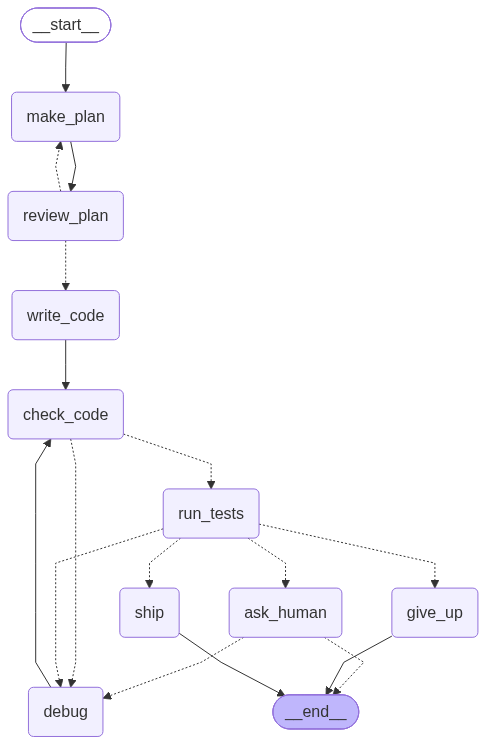

In [22]:
def after_plan_review(j: Job) -> Literal["write_code", "make_plan"]:
    return "make_plan" if j.get("plan_feedback") else "write_code"


def after_check(j: Job) -> Literal["run_tests", "debug"]:
    return "debug" if j["problem"] else "run_tests"          # unsafe or broken code never runs


def after_tests(j: Job) -> Literal["ship", "debug", "ask_human", "give_up"]:
    if not j["report"]["failures"]:
        return "ship"
    if j["attempts"] < j["max_attempts"]:
        return "debug"                                        # the repair loop
    if len(j.get("hints", [])) < MAX_HINTS:
        return "ask_human"                                    # budget spent: escalate
    return "give_up"                                          # even the human budget is spent


def after_human(j: Job) -> Literal["debug", "__end__"]:
    return END if j.get("status") else "debug"


b = StateGraph(Job)
for name, fn in [("make_plan", make_plan), ("review_plan", review_plan), ("write_code", write_code),
                 ("check_code", check_code), ("run_tests", run_tests), ("debug", debug),
                 ("ask_human", ask_human), ("ship", ship), ("give_up", give_up)]:
    b.add_node(name, fn)
b.add_edge(START, "make_plan")
b.add_edge("make_plan", "review_plan")
b.add_conditional_edges("review_plan", after_plan_review)
b.add_edge("write_code", "check_code")
b.add_edge("debug", "check_code")
b.add_conditional_edges("check_code", after_check)
b.add_conditional_edges("run_tests", after_tests)
b.add_conditional_edges("ask_human", after_human)
b.add_edge("ship", END)
b.add_edge("give_up", END)

code_conn = sqlite3.connect("code_agent.db", check_same_thread=False)
coder = b.compile(checkpointer=SqliteSaver(code_conn))
draw(coder)

Two loops, both bounded: `debug → check_code → run_tests → debug` (by `max_attempts`) and
`ask_human → debug` (by `MAX_HINTS`). Two pauses: the plan review and the cry for help.
Everything is checkpointed to `code_agent.db`, so you can stop at either pause and come back
tomorrow.

## Run it

`go()` streams node updates as they happen and stops at a pause.

In [23]:
JOB = {"configurable": {"thread_id": f"NIM-482-{int(time.time())}"}}   # a fresh job each run


def go(inp):
    for update in coder.stream(inp, JOB, stream_mode="updates"):
        for node, change in update.items():
            if node == "__interrupt__":
                payload = change[0].value
                print(f"\n⏸  PAUSED: {payload['step']}")
                return payload
            for line in (change or {}).get("log", []):
                print("  ·", line)
    state = coder.get_state(JOB).values
    print("\n✅", state.get("status"))
    return None


pause = go({"ticket": TICKET, "max_attempts": MAX_ATTEMPTS, "hints": [], "log": []})
display(Markdown(pause["plan"]))

  · make_plan

⏸  PAUSED: review the plan


- Validate `city` against known zones (metros, north-east, others) and handle unknown cities gracefully.  
- Calculate delivery window in business days, excluding Sundays and specified warehouse holidays.  
- If `ordered_at` time is after 18:00, start counting delivery from the next business day.  
- For express deliveries (only valid for metros), halve the delivery window, rounding up to at least 1 day.  
- Return delivery window as a tuple of ISO date strings (`YYYY-MM-DD`) representing earliest and latest delivery dates.  
- Handle edge cases where delivery spans weekends and/or multiple holidays.  
- Ensure time zone consistency if relevant (assume input times are local or UTC as per spec).  
- Validate input format for `ordered_at` and handle parsing errors or invalid dates.

**You're the reviewer.** Read the plan. Does it answer the questions the ticket left open —
18:00, rounding, Pune with express, a holiday after a Sunday? Approve it as-is to see the
repair loop work, or send it back with feedback (exercise 1 does exactly that).

In [24]:
pause = go(Command(resume={"action": "approve"}))

  · plan approved by human


  · write_code
  · check_code: ok
  · run_tests #1: 10/13 passed


  · debug
  · check_code: ok
  · run_tests #2: 12/13 passed


  · debug
  · check_code: ok
  · run_tests #3: 13/13 passed
  · ship

✅ all 13 tests pass after 3 run(s)


If it stopped to ask for help, **read the failing tests** and write a hint the way you'd
nudge a junior colleague: point at the rule, don't paste the answer. The hint below is
deliberately generic, because every run gets stuck somewhere different. In class, replace it
with one that names the rule you can see is being missed.

In [25]:
if pause and pause["step"].startswith("stuck"):
    for f in pause["failures"]:
        print("  ✗", f)
    HINT = ("Take each failing call literally: the expected value IS the policy. For each one, work out which "
            "rule of the ticket it pins down - a time cutoff, a rounding rule, an error case - and change only that.")
    pause = go(Command(resume={"action": "hint", "hint": HINT}))
else:
    print("No human needed on this run.")

No human needed on this run.


## What happened

The whole trajectory, and the code that shipped:

In [26]:
final = coder.get_state(JOB).values
print("status  :", final["status"])
print("journey :", " → ".join(l.split(":")[0] for l in final["log"]))
print("hints   :", final.get("hints"))
display(Markdown(f"```python\n{final['code']}```"))

status  : all 13 tests pass after 3 run(s)
journey : make_plan → plan approved by human → write_code → check_code → run_tests #1 → debug → check_code → run_tests #2 → debug → check_code → run_tests #3 → ship
hints   : []


```python
from datetime import datetime, timedelta

def delivery_window(city, ordered_at, express=False):
    # Define zones with uppercase for case-insensitive matching
    metros = {"MUMBAI", "DELHI", "BENGALURU", "CHENNAI", "KOLKATA", "HYDERABAD"}
    north_east = {"GUWAHATI", "SHILLONG", "IMPHAL", "AGARTALA"}
    warehouse_holidays = {
        datetime(2026, 10, 2).date(),
        datetime(2026, 11, 9).date(),
    }

    city_upper = city.strip().upper()

    # Validate city and assign delivery days
    if city_upper in metros:
        min_days, max_days = 1, 3
    elif city_upper in north_east:
        min_days, max_days = 7, 10
    else:
        # For express orders, city must be metro; else ValueError
        if express:
            raise ValueError("Express delivery only available for metros")
        # Treat unknown or other cities as "everywhere else"
        min_days, max_days = 3, 5

    # Parse ordered_at
    try:
        dt = datetime.strptime(ordered_at, "%Y-%m-%d %H:%M")
    except ValueError:
        raise ValueError("ordered_at must be in 'YYYY-MM-DD HH:MM' format and valid date/time")

    # Check if order time is after 18:00 (6 PM)
    cutoff_hour = 18
    if dt.hour > cutoff_hour or (dt.hour == cutoff_hour and dt.minute > 0):
        # Start counting from next business day
        start_date = dt.date() + timedelta(days=1)
    else:
        start_date = dt.date()

    # Helper to check if a date is a business day
    def is_business_day(d):
        # Sunday is 6 in weekday() (Monday=0)
        if d.weekday() == 6:
            return False
        if d in warehouse_holidays:
            return False
        return True

    # Move start_date forward if it is not a business day
    while not is_business_day(start_date):
        start_date += timedelta(days=1)

    # Adjust delivery days for express (metros only)
    if express:
        # Halve delivery window, round up, minimum 1 day
        def half_days(d):
            return max(1, (d + 1) // 2)
        min_days = half_days(min_days)
        max_days = half_days(max_days)

    # Function to add business days to a date
    def add_business_days(start, days):
        current = start
        added = 0
        while added < days:
            current += timedelta(days=1)
            if is_business_day(current):
                added += 1
        return current

    # Fix: For orders placed exactly at 18:00, count from next day (per test)
    # The original code counts orders at 18:00 as same day, but test expects next day.
    # So adjust cutoff condition to >= 18:00 instead of > 18:00
    # But we already parsed dt and set start_date above, so we need to re-check:
    # Actually, we can fix by changing the cutoff condition above:
    # So let's move that logic before start_date assignment.

    # To fix the above, let's move the cutoff check before start_date assignment:
    # But since we already assigned start_date, let's redo that logic here:

    # Re-implement cutoff logic correctly:
    # Actually, let's do it once at the start:

def delivery_window(city, ordered_at, express=False):
    metros = {"MUMBAI", "DELHI", "BENGALURU", "CHENNAI", "KOLKATA", "HYDERABAD"}
    north_east = {"GUWAHATI", "SHILLONG", "IMPHAL", "AGARTALA"}
    warehouse_holidays = {
        datetime(2026, 10, 2).date(),
        datetime(2026, 11, 9).date(),
    }

    city_upper = city.strip().upper()

    if city_upper in metros:
        min_days, max_days = 1, 3
    elif city_upper in north_east:
        min_days, max_days = 7, 10
    else:
        if express:
            raise ValueError("Express delivery only available for metros")
        min_days, max_days = 3, 5

    try:
        dt = datetime.strptime(ordered_at, "%Y-%m-%d %H:%M")
    except ValueError:
        raise ValueError("ordered_at must be in 'YYYY-MM-DD HH:MM' format and valid date/time")

    def is_business_day(d):
        if d.weekday() == 6:
            return False
        if d in warehouse_holidays:
            return False
        return True

    # Orders placed at or after 18:00 count from next business day
    if dt.hour > 18 or (dt.hour == 18 and dt.minute > 0) or (dt.hour == 18 and dt.minute == 0):
        start_date = dt.date() + timedelta(days=1)
    else:
        start_date = dt.date()

    while not is_business_day(start_date):
        start_date += timedelta(days=1)

    if express:
        def half_days(d):
            return max(1, (d + 1) // 2)
        min_days = half_days(min_days)
        max_days = half_days(max_days)

    def add_business_days(start, days):
        current = start
        added = 0
        while added < days:
            current += timedelta(days=1)
            if is_business_day(current):
                added += 1
        return current

    earliest = add_business_days(start_date, min_days)
    latest = add_business_days(start_date, max_days)

    return (earliest.isoformat(), latest.isoformat())
```

In [27]:
# Did it really pass? Run the hidden tests one more time, independently of the graph.
print(run_hidden_tests(final["code"]))

{'total': 13, 'failures': []}


Look at the journey. The first version almost certainly didn't pass: the ticket was vague,
and the model guessed. The failing tests told it which guesses were wrong, and the loop fixed
them one run at a time. When the tests alone weren't enough, a human spent ten seconds on a
hint instead of an hour on the code.

Runs differ: sometimes the first repair fixes everything, sometimes it needs the human.
The graph handles every case, because every case is an edge.

### Passing tests is not the same as good code

Now **read the code that shipped**. In the run saved in this notebook it passed all 13
tests — and still contained a half-finished first version of the function, a trail of
*"Actually, let's…"* comments, and then a second `def delivery_window` that silently replaced
the first. Python allows that; the tests can't see it; a reviewer would reject it in seconds.

Tests tell you the code is **correct**. They don't tell you it's **mergeable**. That's the
case for one more gate before `ship` — a static rule, an LLM reviewer, or a human (exercise 6).

### Time travel, one more time

Every attempt is a checkpoint. Pull out the code from each test run to see the repair in
slow motion:

In [28]:
history = list(coder.get_state_history(JOB))           # newest first
for i in reversed(range(1, len(history))):
    before, after = history[i], history[i - 1]           # the checkpoints either side of a test run
    if before.next == ("run_tests",):
        r = after.values["report"]
        print(f"test run {after.values['attempts']}: {r['total'] - len(r['failures']):>2}/{r['total']} passed"
              f"   ({len(before.values['code'].splitlines())} lines of code)")

test run 1: 10/13 passed   (76 lines of code)
test run 2: 12/13 passed   (77 lines of code)
test run 3: 13/13 passed   (142 lines of code)


---
# What you take forward

- `interrupt(payload)` pauses a node; `Command(resume=answer)` continues it. **The node reruns
  from the top**, so side effects go after the interrupt.
- Approve / edit / reject is ~15 lines: `Command(goto=…, update=…)` plus replace-by-id.
- A **durable checkpointer** turns a pause into something that survives restarts. The
  `thread_id` is your job id.
- A **repair loop** needs something real to check against (tests), a budget, and an
  escalation path when the budget runs out — to a human, who has a budget too.
- Put the human where they're **cheapest**: approving a plan costs seconds; debugging code
  the agent wrote from a wrong plan costs much more.

**Next session:** more than one agent — a supervisor, a team, and work fanned out in parallel.

---
## Exercises

**1. Review the plan properly.** Rerun from `go(...)` and, at the plan review, send it back:
`Command(resume={"action": "revise", "feedback": "18:00 counts as after 6 pm. Round express up. Express outside metros raises ValueError."})`.
How many test runs does it take now?

**2. Gate the code, not just the plan.** Add a pause *before* `run_tests` that shows the code
and asks "run it?". (Hint: `interrupt` in a new node, or `compile(interrupt_before=["run_tests"])`.)

**3. Break the budget.** Set `MAX_ATTEMPTS = 1`. How often does it need a human now?

**4. A cheaper coder.** Use `gpt-4.1-nano` for `write_code` and `debug` only. Does the loop
still get there? What does that say about using tests plus a cheap model versus a big model once?

**5. The inbox.** Using Part 3, write `pending_approvals(db_path)` that lists every job parked
at a pause with its payload — the backend of an approvals page.

**6. A code review before shipping.** Add a `review_code` node between `run_tests` and `ship`.
Start cheap: make `static_check` reject a module that defines `delivery_window` twice. Then try
an LLM reviewer with structured output (`approved: bool, feedback: str`) that sends the code
back to `debug` — what budget does that loop need?